In [49]:
# ---------------------------------------------------------
# BIBLIOTHEKEN UND MODELLPARAMETER
# ---------------------------------------------------------

from matplotlib import pyplot as plt
from optimizer import Optimizer

plt.rcParams["figure.figsize"] = (14, 4)

# Allgemeine Modellparameter
DATA_FOLDER = "data_test"
N = 96                    # 96 Zeitschritte à 15 Minuten
DT = 0.25                 # Stunden pro Zeitschritt
PROSUMER = 0
T_EXAMPLE = 40

# Statischer Aufteilungsschlüssel
ALLOCATION_KEYS = {
    1: 0.5,
    2: 0.3,
    3: 0.2
}

# Zentrale Preisparameter [€/kWh]
PRICES = {
    "p_grid": 0.37,                 # Haushaltsstrompreis [€/kWh]
    "p_sharing": 0.13,              # Vergütung Prosumer [€/kWh] = Energy-Sharing-Verkaufspreis
    "p_netzentgelte": 0.09,         # Netzentgelte [€/kWh]
    "p_umlagen_abgaben": 0.07,      # Umlagen und Abgaben [€/kWh]
    "p_stromsteuer": 0.02,          # Stromsteuer [€/kWh]
    "p_servicegebühr": 0.01,        # Servicegebühr [€/kWh]
    "p_feed_in": 0.08,              # Einspeisevergütung ohne ES [€/kWh]
    "p_residual": 0.00              # Vergütung Restüberschuss mit ES [€/kWh]
}

# Endpreis für Consumer berechnen
PRICES["p_sharing_consumer"] = (
    PRICES["p_sharing"]
    + PRICES["p_netzentgelte"]
    + PRICES["p_umlagen_abgaben"]
    + PRICES["p_stromsteuer"]
    + PRICES["p_servicegebühr"]
)

print(f"Energy-Sharing-Endpreis: {PRICES['p_sharing_consumer']:.3f} €/kWh")

assert abs(sum(ALLOCATION_KEYS.values()) - 1.0) < 1e-9

print("=== Modellparameter ===")
for name, price in PRICES.items():
    print(f"{name:<22}: {price:.2f} €/kWh")

print(f"\nProsumer:          User {PROSUMER}")
print(f"Aufteilung:        {ALLOCATION_KEYS}")
print(f"Zeitschritte:      {N}")
print(f"Betrachtungsdauer: {N * DT:.0f} h")

Energy-Sharing-Endpreis: 0.320 €/kWh
=== Modellparameter ===
p_grid                : 0.37 €/kWh
p_sharing             : 0.13 €/kWh
p_netzentgelte        : 0.09 €/kWh
p_umlagen_abgaben     : 0.07 €/kWh
p_stromsteuer         : 0.02 €/kWh
p_servicegebühr       : 0.01 €/kWh
p_feed_in             : 0.08 €/kWh
p_residual            : 0.00 €/kWh
p_sharing_consumer    : 0.32 €/kWh

Prosumer:          User 0
Aufteilung:        {1: 0.5, 2: 0.3, 3: 0.2}
Zeitschritte:      96
Betrachtungsdauer: 24 h


In [22]:
# ---------------------------------------------------------
# DATEN LADEN UND OPTIMIERER ERSTELLEN
# ---------------------------------------------------------

opt = Optimizer.from_folder2(DATA_FOLDER)

print("=== Eingangsdaten ===")
print(f"Preisprofile [€/kWh]:       {opt.price.shape}")
print(f"Verbrauchsprofile [kWh]:    {opt.cons.shape}")
print(f"Solarprofile [kWh]:         {opt.sun.shape}")
print(f"PV-Leistungen [kWh]:        {opt.pv}")
print(f"Batteriekapazitäten [kWh]:  {opt.battery}")

assert opt.cons.shape[1] >= N
assert opt.sun.shape[1] >= N
assert len(opt.pv) == opt.cons.shape[0]

print("\nDaten erfolgreich geladen.")

=== Eingangsdaten ===
Preisprofile [€/kWh]:       (4, 96)
Verbrauchsprofile [kWh]:    (4, 96)
Solarprofile [kWh]:         (4, 96)
PV-Leistungen [kWh]:        [5. 0. 0. 0.]
Batteriekapazitäten [kWh]:  [0. 0. 0. 0.]

Daten erfolgreich geladen.


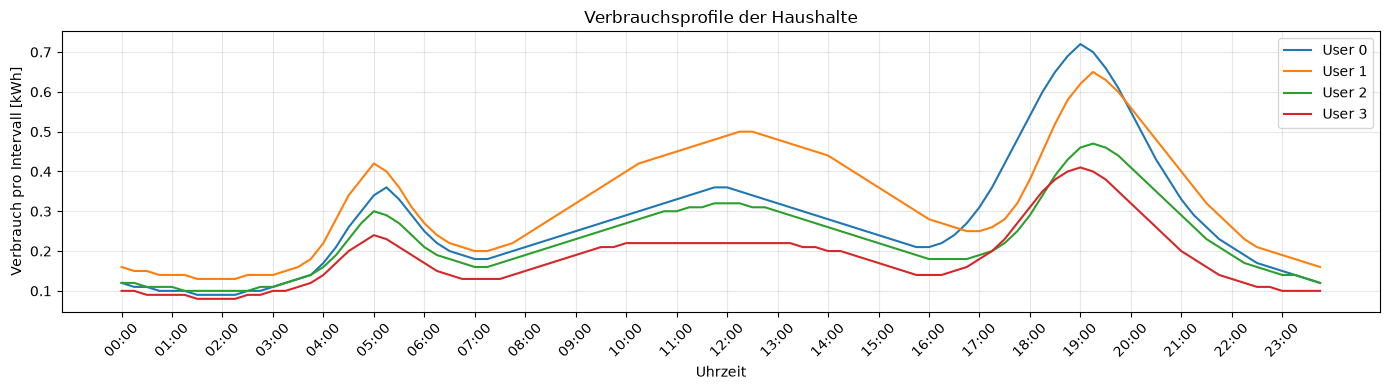

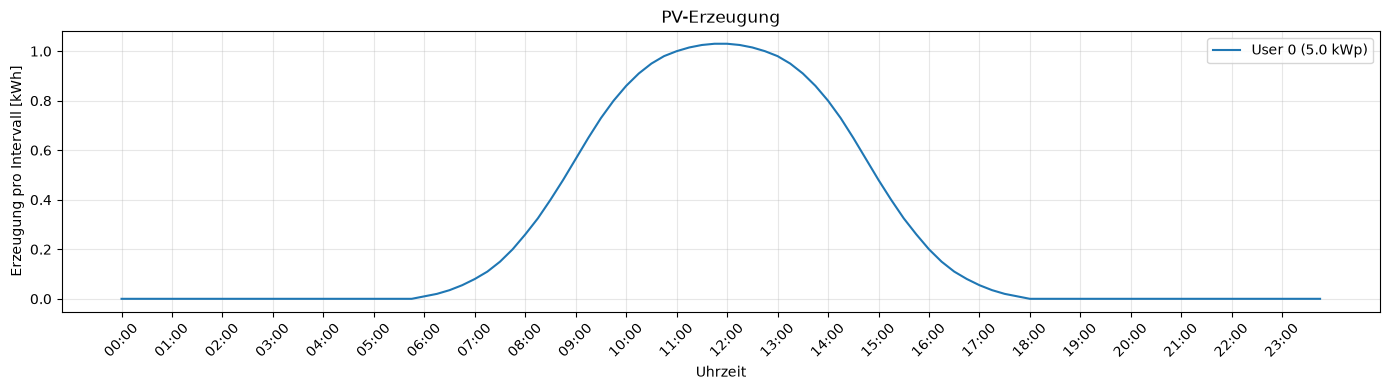

In [46]:
# ---------------------------------------------------------
# VERBRAUCHS- UND ERZEUGUNGSPROFILE PLOTTEN
# ---------------------------------------------------------

# Zeitachse: 4 Zeitschritte pro Stunde
ticks = range(0, N, 4)
labels = [f"{t // 4:02d}:00" for t in ticks]

# Verbrauchsprofile
plt.figure()

for user in range(opt.cons.shape[0]):
    plt.plot(
        range(N),
        opt.cons[user, :N],
        label=f"User {user}"
    )

plt.title("Verbrauchsprofile der Haushalte")
plt.xlabel("Uhrzeit")
plt.ylabel("Verbrauch pro Intervall [kWh]")
plt.xticks(ticks, labels, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# PV-Erzeugung
plt.figure()

for user in range(len(opt.pv)):
    if opt.pv[user] > 0:
        generation = opt.pv[user] * opt.sun[user, :N]

        plt.plot(
            range(N),
            generation,
            label=f"User {user} ({opt.pv[user]:.1f} kWp)"
        )

plt.title("PV-Erzeugung")
plt.xlabel("Uhrzeit")
plt.ylabel("Erzeugung pro Intervall [kWh]")
plt.xticks(ticks, labels, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [53]:
# ---------------------------------------------------------
# ENERGY-SHARING-MODELL ERSTELLEN UND LÖSEN
# ---------------------------------------------------------

solver = opt.static_sharing_solver(
    allocation_keys=ALLOCATION_KEYS,
    prosumer=PROSUMER,
    p_p2p=PRICES["p_sharing"],
    p_feed_in=PRICES["p_feed_in"],
    residual_price=PRICES["p_residual"]
)

solver.solve(N)

# Energiebilanz
balance = solver.prosumer_energy_balance(N)

# Wirtschaftlichkeit Prosumer
sharing = solver.prosumer_costs(
    N=N,
    grid_price=PRICES["p_grid"]
)

reference = solver.prosumer_reference_costs(
    N=N,
    grid_price=PRICES["p_grid"]
)

# Wirtschaftlichkeit Consumer
consumers = solver.consumer_costs(
    N=N,
    grid_price=PRICES["p_grid"],
    sharing_price=PRICES["p_sharing_consumer"]
)

print("=== Energy-Sharing-Modell ===")
print("Berechnung abgeschlossen.")

=== Energy-Sharing-Modell ===
Berechnung abgeschlossen.


## 1. Energiebilanz – Prosumer

,Energie [kWh]
PV-Erzeugung,25.28
Energy Sharing,24.85
Eigenverbrauch,0.43
Netzeinspeisung (Überschuss),0.00
Stromverbrauch Prosumer,26.60
Reststrombezug,26.17



Aufteilung der PV-Erzeugung:
  Energy Sharing:  98.3 %
  Eigenverbrauch:  1.7 %
  Netzeinspeisung: 0.0 %


### 2. Energiebilanz – Consumer

,Verbrauch [kWh],Sharing [kWh],Netzbezug [kWh],PV-Deckungsgrad [%]
Teilnehmer,,,,
Consumer 1,31.19,12.210,18.980,39.147
Consumer 2,22.04,7.584,14.456,34.410
Consumer 3,17.67,5.056,12.614,28.613


...

,Wert,Einheit
Kennzahl,,
Gesamtverbrauch,97.500,kWh
PV-Erzeugung,25.280,kWh
PV-Eigenverbrauch Prosumer,0.430,kWh
Geteilte PV-Energie,24.850,kWh
Gesamter Netzbezug,72.220,kWh
PV-Netzeinspeisung,0.000,kWh
PV-Nutzung innerhalb der Gemeinschaft,25.280,kWh
Autarkiegrad der ESC [%],25.928,%
PV-Nutzungsgrad [%],100.000,%



Der Autarkiegrad beschreibt, welcher Anteil des gesamten Stromverbrauchs 
durch die gemeinschaftlich genutzte PV-Erzeugung gedeckt wird.

Der PV-Nutzungsgrad zeigt dagegen, welcher Anteil der erzeugten 
PV-Energie innerhalb der Gemeinschaft genutzt wird.


### 4. Plausibilitäts- und Bilanzkontrolle

,Max. Abweichung [kWh],Status
Prüfung,,
PV-Erzeugungsbilanz,1.110223e-16,OK
Prosumer-Verbrauchsbilanz,0.000000e+00,OK
Consumer-Verbrauchsbilanzen,3.469447e-17,OK
Sharing-Abgleich Prosumer/Consumer,1.110223e-16,OK
Pyomo-Abgleich Netzbezug,1.665335e-16,OK
Pyomo-Abgleich Netzeinspeisung,0.000000e+00,OK



Alle Energiebilanzprüfungen erfolgreich.


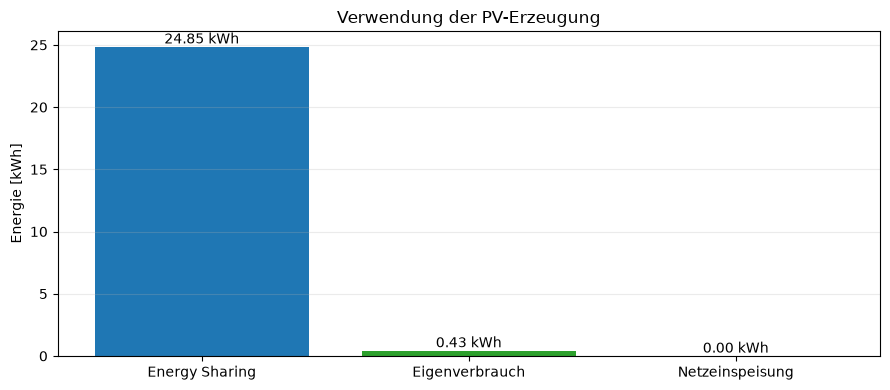

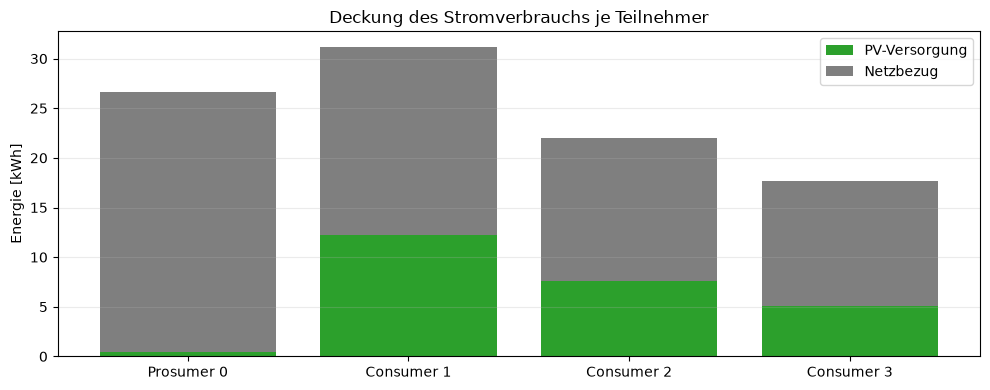

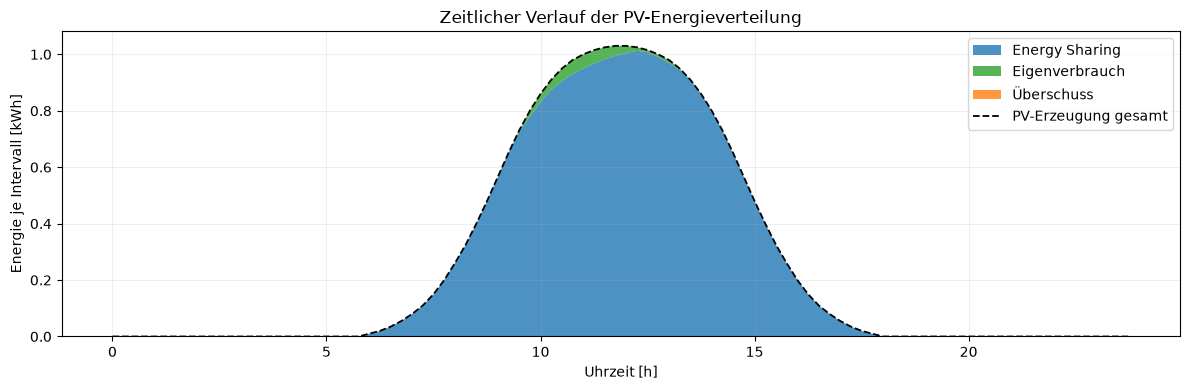

### 5. Detailanalyse – Zeitschritt 40 (10.00 h)

,Verbrauch [kWh],PV-Versorgung [kWh],Netzbezug [kWh]
Teilnehmer,,,
Prosumer 0,0.29,0.030,0.260
Consumer 1,0.40,0.400,0.000
Consumer 2,0.27,0.258,0.012
Consumer 3,0.22,0.172,0.048



PV-Erzeugung:           0.860 kWh
Energy Sharing:         0.830 kWh
Eigenverbrauch:         0.030 kWh
PV-Überschuss:          0.000 kWh


In [75]:

# ============================================================
# ENERGIEBILANZ DER ENERGIEGEMEINSCHAFT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. HILFSFUNKTIONEN UND DATEN
# ------------------------------------------------------------

def fmt_energy(value):
    return f"{value:.3f} kWh"

def show_energy_table(title, dataframe):
    display(Markdown(f"### {title}"))
    display(dataframe.round(3))

# Energiedaten je Zeitschritt (kWh pro Intervall)
generation = np.array(balance["generation"], dtype=float)
shared = np.array(balance["shared"], dtype=float)
self_consumption = np.array(
    balance["self_consumption_own_pv"], dtype=float
)
prosumer_grid = np.array(balance["grid_import"], dtype=float)
surplus = np.array(balance["surplus"], dtype=float)

prosumer_demand = np.array([
    solver.consf(PROSUMER, t) for t in range(N)
])

time_hours = np.arange(N) * DT
consumer_ids = sorted(ALLOCATION_KEYS)

# ------------------------------------------------------------
# 2. ENERGIEBILANZ PROSUMER
# ------------------------------------------------------------

E_generation = generation.sum()
E_shared = shared.sum()
E_self = self_consumption.sum()
E_grid_prosumer = prosumer_grid.sum()
E_surplus = surplus.sum()
E_demand_prosumer = prosumer_demand.sum()

df_prosumer_energy = pd.DataFrame({
    "Energie [kWh]": {
        "PV-Erzeugung": E_generation,
        "Energy Sharing": E_shared,
        "Eigenverbrauch": E_self,
        "Netzeinspeisung (Überschuss)": E_surplus,
        "Stromverbrauch Prosumer": E_demand_prosumer,
        "Reststrombezug": E_grid_prosumer
    }
})

display(Markdown("## 1. Energiebilanz – Prosumer"))
display(df_prosumer_energy.round(3))

print("\nAufteilung der PV-Erzeugung:")
print(f"  Energy Sharing:  {E_shared / E_generation * 100:.1f} %"
      if E_generation > 0 else "  Keine PV-Erzeugung")
print(f"  Eigenverbrauch:  {E_self / E_generation * 100:.1f} %"
      if E_generation > 0 else "")
print(f"  Netzeinspeisung: {E_surplus / E_generation * 100:.1f} %"
      if E_generation > 0 else "")

# ------------------------------------------------------------
# 3. ENERGIEBILANZ CONSUMER
# ------------------------------------------------------------

consumer_data = []
consumer_timeseries = {}

for c in consumer_ids:

    demand = np.array([
        solver.consf(c, t) for t in range(N)
    ])

    es = np.array([
        solver.model.imported[c, t].value
        for t in range(N)
    ], dtype=float)

    grid = np.array([
        solver.model.el_in[c, t].value
        for t in range(N)
    ], dtype=float)

    consumer_timeseries[c] = {
        "demand": demand,
        "shared": es,
        "grid": grid
    }

    E_demand = demand.sum()
    E_es = es.sum()
    E_grid = grid.sum()

    consumer_data.append({
        "Teilnehmer": f"Consumer {c}",
        "Verbrauch [kWh]": E_demand,
        "Sharing [kWh]": E_es,
        "Netzbezug [kWh]": E_grid,
        "PV-Deckungsgrad [%]": (
            100 * E_es / E_demand
            if E_demand > 0 else 0
        )
    })

df_consumer_energy = pd.DataFrame(
    consumer_data
).set_index("Teilnehmer")

show_energy_table(
    "2. Energiebilanz – Consumer",
    df_consumer_energy
)

# ------------------------------------------------------------
# 4. GESAMTBILANZ DER ENERGIEGEMEINSCHAFT
# ------------------------------------------------------------

E_consumer_demand = df_consumer_energy["Verbrauch [kWh]"].sum()
E_consumer_shared = df_consumer_energy["Sharing [kWh]"].sum()
E_consumer_grid = df_consumer_energy["Netzbezug [kWh]"].sum()

E_total_demand = E_demand_prosumer + E_consumer_demand
E_total_grid = E_grid_prosumer + E_consumer_grid
E_pv_used = E_self + E_consumer_shared

# Physikalische PV-Nutzung innerhalb der Gemeinschaft
self_sufficiency = (
    100 * E_pv_used / E_total_demand
    if E_total_demand > 0 else 0
)

pv_utilization = (
    100 * E_pv_used / E_generation
    if E_generation > 0 else 0
)

df_community_energy = pd.DataFrame({
    "Kennzahl": [
        "Gesamtverbrauch",
        "PV-Erzeugung",
        "PV-Eigenverbrauch Prosumer",
        "Geteilte PV-Energie",
        "Gesamter Netzbezug",
        "PV-Netzeinspeisung",
        "PV-Nutzung innerhalb der Gemeinschaft",
        "Autarkiegrad der ESC [%]",
        "PV-Nutzungsgrad [%]"
    ],
    "Wert": [
        E_total_demand,
        E_generation,
        E_self,
        E_consumer_shared,
        E_total_grid,
        E_surplus,
        E_pv_used,
        self_sufficiency,
        pv_utilization
    ],
    "Einheit": [
        "kWh", "kWh", "kWh", "kWh",
        "kWh", "kWh", "kWh", "%", "%"
    ]
})

show_energy_table(
    "3. Gesamtbilanz der Energiegemeinschaft",
    df_community_energy.set_index("Kennzahl")
)

print("\nDer Autarkiegrad beschreibt, welcher Anteil des gesamten Stromverbrauchs " \
"\ndurch die gemeinschaftlich genutzte PV-Erzeugung gedeckt wird.")

print("\nDer PV-Nutzungsgrad zeigt dagegen, welcher Anteil der erzeugten " \
"\nPV-Energie innerhalb der Gemeinschaft genutzt wird.")

# ------------------------------------------------------------
# 5. AUTOMATISCHE ENERGIEBILANZPRÜFUNGEN
# ------------------------------------------------------------

# PV-Erzeugung = Sharing + Eigenverbrauch + Überschuss
pv_error = generation - shared - self_consumption - surplus

# Prosumer-Verbrauch = Eigenverbrauch + Netzbezug
prosumer_error = (
    prosumer_demand - self_consumption - prosumer_grid
)

# Summe Consumer-Sharing = vom Prosumer abgegebene Energie
shared_consumer_ts = np.sum([
    consumer_timeseries[c]["shared"]
    for c in consumer_ids
], axis=0)

sharing_error = shared - shared_consumer_ts

# Verbraucherbilanz je Zeitschritt
consumer_errors = []

for c in consumer_ids:
    d = consumer_timeseries[c]

    consumer_errors.extend(
        d["demand"] - d["shared"] - d["grid"]
    )

# Abgleich mit Pyomo
import_error = np.array([
    prosumer_grid[t] - solver.model.el_in[PROSUMER, t].value
    for t in range(N)
])

export_error = np.array([
    surplus[t] - solver.model.el_out[PROSUMER, t].value
    for t in range(N)
])

checks = {
    "PV-Erzeugungsbilanz": np.max(np.abs(pv_error)),
    "Prosumer-Verbrauchsbilanz": np.max(np.abs(prosumer_error)),
    "Consumer-Verbrauchsbilanzen": np.max(np.abs(consumer_errors)),
    "Sharing-Abgleich Prosumer/Consumer": np.max(np.abs(sharing_error)),
    "Pyomo-Abgleich Netzbezug": np.max(np.abs(import_error)),
    "Pyomo-Abgleich Netzeinspeisung": np.max(np.abs(export_error))
}

tolerance = 1e-6

df_checks = pd.DataFrame([
    {
        "Prüfung": name,
        "Max. Abweichung [kWh]": error,
        "Status": "OK" if error < tolerance else "FEHLER"
    }
    for name, error in checks.items()
]).set_index("Prüfung")

display(Markdown("### 4. Plausibilitäts- und Bilanzkontrolle"))
display(df_checks)

if all(error < tolerance for error in checks.values()):
    print("\nAlle Energiebilanzprüfungen erfolgreich.")
else:
    print("\nAchtung: Mindestens eine Energiebilanz ist nicht erfüllt.")

# ------------------------------------------------------------
# 6. VISUALISIERUNG: PV-VERWENDUNG
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 4))

categories = [
    "Energy Sharing",
    "Eigenverbrauch",
    "Netzeinspeisung"
]

values = [E_shared, E_self, E_surplus]

bars = ax.bar(
    categories,
    values,
    color=["tab:blue", "tab:green", "tab:orange"]
)

ax.set_ylabel("Energie [kWh]")
ax.set_title("Verwendung der PV-Erzeugung")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} kWh",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. VISUALISIERUNG: VERSORGUNG DER TEILNEHMER
# ------------------------------------------------------------

participants = [f"Prosumer {PROSUMER}"] + [
    f"Consumer {c}" for c in consumer_ids
]

local_pv = [E_self] + [
    consumer_timeseries[c]["shared"].sum()
    for c in consumer_ids
]

grid_imports = [E_grid_prosumer] + [
    consumer_timeseries[c]["grid"].sum()
    for c in consumer_ids
]

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    participants,
    local_pv,
    label="PV-Versorgung",
    color="tab:green"
)

ax.bar(
    participants,
    grid_imports,
    bottom=local_pv,
    label="Netzbezug",
    color="tab:gray"
)

ax.set_ylabel("Energie [kWh]")
ax.set_title("Deckung des Stromverbrauchs je Teilnehmer")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. ZEITLICHER VERLAUF DER PV-VERWENDUNG
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 4))

ax.stackplot(
    time_hours,
    shared,
    self_consumption,
    surplus,
    labels=["Energy Sharing", "Eigenverbrauch", "Überschuss"],
    colors=["tab:blue", "tab:green", "tab:orange"],
    alpha=0.8
)

ax.plot(
    time_hours,
    generation,
    color="black",
    linewidth=1.3,
    linestyle="--",
    label="PV-Erzeugung gesamt"
)

ax.set_xlabel("Uhrzeit [h]")
ax.set_ylabel("Energie je Intervall [kWh]")
ax.set_title("Zeitlicher Verlauf der PV-Energieverteilung")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. DETAILANALYSE EINES ZEITSCHRITTS
# ------------------------------------------------------------

t = T_EXAMPLE

display(Markdown(
    f"### 5. Detailanalyse – Zeitschritt {t} "
    f"({t * DT:.2f} h)"
))

detail_rows = [{
    "Teilnehmer": f"Prosumer {PROSUMER}",
    "Verbrauch [kWh]": prosumer_demand[t],
    "PV-Versorgung [kWh]": self_consumption[t],
    "Netzbezug [kWh]": prosumer_grid[t]
}]

for c in consumer_ids:
    d = consumer_timeseries[c]

    detail_rows.append({
        "Teilnehmer": f"Consumer {c}",
        "Verbrauch [kWh]": d["demand"][t],
        "PV-Versorgung [kWh]": d["shared"][t],
        "Netzbezug [kWh]": d["grid"][t]
    })

df_detail = pd.DataFrame(detail_rows).set_index("Teilnehmer")

display(df_detail.round(3))

print(f"\nPV-Erzeugung:           {generation[t]:.3f} kWh")
print(f"Energy Sharing:         {shared[t]:.3f} kWh")
print(f"Eigenverbrauch:         {self_consumption[t]:.3f} kWh")
print(f"PV-Überschuss:          {surplus[t]:.3f} kWh")


## Wirtschaftliche Analyse der Energiegemeinschaft

Betrachtungszeitraum:      24.0 Stunden
PV-Erzeugung:              25,28 kWh
Geteilte PV-Energie:       24,85 kWh
Eigenverbrauch Prosumer:   0,43 kWh
Restüberschuss:            0,00 kWh

Haushaltsstrompreis:       37.00 ct/kWh
P2P-Vergütung:             13.00 ct/kWh
Sharing-Endpreis:          32.00 ct/kWh


### 1. Wirtschaftlicher Vergleich – Prosumer

,Ohne ES,Mit ES,Veränderung
Netzbezugskosten,"5,98 €","9,68 €","3,70 €"
Vermarktungserlöse,"1,19 €","3,23 €","2,04 €"
Nettostromkosten,"4,79 €","6,45 €","1,66 €"



Wirtschaftlicher Vorteil Prosumer: -1,66 €
Ergebnis: Der Prosumer hat durch Energy Sharing höhere Nettostromkosten.


...

,Preis [ct/kWh],Energie [kWh],Betrag [€]
Zahlungsempfänger / Bestandteil,,,
Vergütung Prosumer,13.00,24.85,"3,23 €"
Netzentgelte,9.00,24.85,"2,24 €"
Umlagen und Abgaben,7.00,24.85,"1,74 €"
Stromsteuer,2.00,24.85,"0,50 €"
Servicegebühr,1.00,24.85,"0,25 €"



Gesamtzahlung für geteilte Energie: 7,95 €
Summe aller Preisbestandteile:      7,95 €
Bilanzdifferenz:                    0.00000000 €


### 4. Gesamtbewertung der Energiegemeinschaft

,Wirtschaftlicher Vorteil [€]
Teilnehmer,
Prosumer,"-1,66 €"
Consumer gesamt,"1,24 €"
Energiegemeinschaft gesamt,"-0,42 €"



Interpretation:
Prosumer:       -1,66 €
Consumer:       1,24 €
Gesamteffekt:   -0,42 €
Die Haushalte erzielen zusammen einen finanziellen Nachteil.


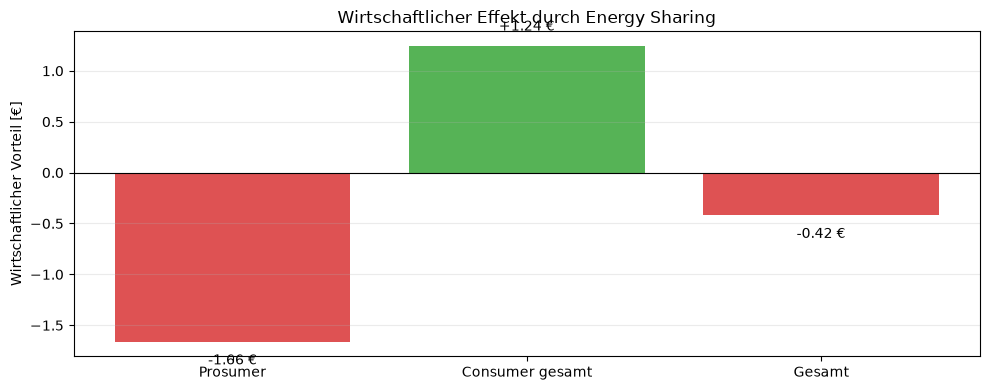

In [70]:

# ============================================================
# WIRTSCHAFTLICHE AUSWERTUNG UND ZAHLUNGSBILANZ
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. HILFSFUNKTIONEN
# ------------------------------------------------------------

def euro(x):
    """Formatiert einen Betrag in Euro."""
    return f"{x:,.2f} €".replace(",", "X").replace(".", ",").replace("X", ".")

def kwh(x):
    """Formatiert eine Energiemenge."""
    return f"{x:,.2f} kWh".replace(",", "X").replace(".", ",").replace("X", ".")

def show_table(title, df):
    display(Markdown(f"### {title}"))
    display(df)


# ------------------------------------------------------------
# 2. GRUNDLEGENDE KENNZAHLEN
# ------------------------------------------------------------

E_shared = sum(balance["shared"])
E_generation = sum(balance["generation"])
E_self = sum(balance["self_consumption_own_pv"])
E_surplus = sum(balance["surplus"])

p_grid = PRICES["p_grid"]
p_p2p = PRICES["p_sharing"]
p_es = PRICES["p_sharing_consumer"]

display(Markdown("## Wirtschaftliche Analyse der Energiegemeinschaft"))

print(f"Betrachtungszeitraum:      {N * DT:.1f} Stunden")
print(f"PV-Erzeugung:              {kwh(E_generation)}")
print(f"Geteilte PV-Energie:       {kwh(E_shared)}")
print(f"Eigenverbrauch Prosumer:   {kwh(E_self)}")
print(f"Restüberschuss:            {kwh(E_surplus)}")
print()
print(f"Haushaltsstrompreis:       {p_grid * 100:.2f} ct/kWh")
print(f"P2P-Vergütung:             {p_p2p * 100:.2f} ct/kWh")
print(f"Sharing-Endpreis:          {p_es * 100:.2f} ct/kWh")


# ------------------------------------------------------------
# 3. WIRTSCHAFTLICHER VERGLEICH PROSUMER
# ------------------------------------------------------------

revenue_reference = reference["feed_in_revenue"]

revenue_sharing = (
    sharing["sharing_revenue"]
    + sharing["residual_revenue"]
)

prosumer_rows = {
    "Netzbezugskosten": (
        reference["grid_cost"],
        sharing["grid_cost"]
    ),
    "Vermarktungserlöse": (
        revenue_reference,
        revenue_sharing
    ),
    "Nettostromkosten": (
        reference["net_cost"],
        sharing["net_cost"]
    )
}

df_prosumer = pd.DataFrame.from_dict(
    prosumer_rows,
    orient="index",
    columns=["Ohne ES", "Mit ES"]
)

df_prosumer["Veränderung"] = (
    df_prosumer["Mit ES"] - df_prosumer["Ohne ES"]
)

show_table(
    "1. Wirtschaftlicher Vergleich – Prosumer",
    df_prosumer.style.format(euro)
    .set_caption("Positive Veränderungen der Nettostromkosten bedeuten Mehrkosten.")
)

prosumer_savings = (
    reference["net_cost"] - sharing["net_cost"]
)

print(f"\nWirtschaftlicher Vorteil Prosumer: {euro(prosumer_savings)}")

if prosumer_savings >= 0:
    print("Ergebnis: Der Prosumer profitiert wirtschaftlich von Energy Sharing.")
else:
    print("Ergebnis: Der Prosumer hat durch Energy Sharing höhere Nettostromkosten.")


# ------------------------------------------------------------
# 4. WIRTSCHAFTLICHER VERGLEICH CONSUMER
# ------------------------------------------------------------

consumer_rows = []
total_consumer_savings = 0.0

for c, data in sorted(consumers.items()):

    consumption = sum(solver.consf(c, t) for t in range(N))
    shared_energy = sum(
        min(ALLOCATION_KEYS[c] * balance["generation"][t],
            solver.consf(c, t))
        for t in range(N)
    )
    grid_energy = consumption - shared_energy

    consumer_rows.append({
        "Consumer": f"Consumer {c}",
        "Verbrauch [kWh]": consumption,
        "Sharing [kWh]": shared_energy,
        "Netzbezug [kWh]": grid_energy,
        "Ohne ES [€]": data["cost_without_es"],
        "Mit ES [€]": data["cost_with_es"],
        "Ersparnis [€]": data["savings"],
        "Ersparnis [%]": (
            100 * data["savings"] / data["cost_without_es"]
            if data["cost_without_es"] > 0 else 0
        )
    })

    total_consumer_savings += data["savings"]

df_consumers = pd.DataFrame(consumer_rows).set_index("Consumer")

show_table(
    "2. Wirtschaftlicher Vergleich – Consumer",
    df_consumers.style.format({
        "Verbrauch [kWh]": "{:.2f}",
        "Sharing [kWh]": "{:.2f}",
        "Netzbezug [kWh]": "{:.2f}",
        "Ohne ES [€]": euro,
        "Mit ES [€]": euro,
        "Ersparnis [€]": euro,
        "Ersparnis [%]": "{:.1f} %"
    })
)

print(f"\nGesamtersparnis Consumer: {euro(total_consumer_savings)}")


# ------------------------------------------------------------
# 5. ZAHLUNGSBILANZ ENERGY SHARING
# ------------------------------------------------------------

payment_components = {
    "Vergütung Prosumer": PRICES["p_sharing"],
    "Netzentgelte": PRICES["p_netzentgelte"],
    "Umlagen und Abgaben": PRICES["p_umlagen_abgaben"],
    "Stromsteuer": PRICES["p_stromsteuer"],
    "Servicegebühr": PRICES["p_servicegebühr"]
}

payment_rows = []

for name, price in payment_components.items():
    payment_rows.append({
        "Zahlungsempfänger / Bestandteil": name,
        "Preis [ct/kWh]": price * 100,
        "Energie [kWh]": E_shared,
        "Betrag [€]": E_shared * price
    })

df_payments = pd.DataFrame(payment_rows).set_index(
    "Zahlungsempfänger / Bestandteil"
)

show_table(
    "3. Zahlungsbilanz der geteilten Energie",
    df_payments.style.format({
        "Preis [ct/kWh]": "{:.2f}",
        "Energie [kWh]": "{:.2f}",
        "Betrag [€]": euro
    })
)

total_sharing_payments = E_shared * p_es
total_components = df_payments["Betrag [€]"].sum()

print(f"\nGesamtzahlung für geteilte Energie: {euro(total_sharing_payments)}")
print(f"Summe aller Preisbestandteile:      {euro(total_components)}")

payment_error = total_sharing_payments - total_components

print(f"Bilanzdifferenz:                    {payment_error:.8f} €")

assert abs(payment_error) < 1e-8, "Zahlungsbilanz nicht erfüllt!"

# Zusätzlich: Prosumer-Erlös muss mit der P2P-Zahlung übereinstimmen
assert abs(
    sharing["sharing_revenue"] - E_shared * p_p2p
) < 1e-6, "Prosumer-Vergütung nicht konsistent!"


# ------------------------------------------------------------
# 6. GESAMTBEWERTUNG DER ENERGIEGEMEINSCHAFT
# ------------------------------------------------------------

community_benefit = (
    prosumer_savings + total_consumer_savings
)

df_community = pd.DataFrame({
    "Teilnehmer": [
        "Prosumer",
        "Consumer gesamt",
        "Energiegemeinschaft gesamt"
    ],
    "Wirtschaftlicher Vorteil [€]": [
        prosumer_savings,
        total_consumer_savings,
        community_benefit
    ]
}).set_index("Teilnehmer")

show_table(
    "4. Gesamtbewertung der Energiegemeinschaft",
    df_community.style.format(euro)
)

print("\nInterpretation:")
print(f"Prosumer:       {euro(prosumer_savings)}")
print(f"Consumer:       {euro(total_consumer_savings)}")
print(f"Gesamteffekt:   {euro(community_benefit)}")

if community_benefit > 0:
    print("Die Haushalte erzielen zusammen einen positiven finanziellen Vorteil.")
elif community_benefit < 0:
    print("Die Haushalte erzielen zusammen einen finanziellen Nachteil.")
else:
    print("Es entsteht kein finanzieller Gesamtvorteil.")


# ------------------------------------------------------------
# 7. GRAFISCHE AUSWERTUNG
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4))

labels = ["Prosumer", "Consumer gesamt", "Gesamt"]
values = [
    prosumer_savings,
    total_consumer_savings,
    community_benefit
]

colors = [
    "tab:green" if v >= 0 else "tab:red"
    for v in values
]

bars = ax.bar(labels, values, color=colors, alpha=0.8)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Wirtschaftlicher Vorteil [€]")
ax.set_title("Wirtschaftlicher Effekt durch Energy Sharing")
ax.grid(axis="y", alpha=0.25)

for bar, value in zip(bars, values):
    offset = 0.12 if value >= 0 else -0.12
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + offset,
        f"{value:+.2f} €",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()


In [41]:
# ---------------------------------------------------------
# DETAILANALYSE EINES ZEITSCHRITTS
# ---------------------------------------------------------

t = T_EXAMPLE

print(f"=== Detailanalyse bei t={t} ({t * 15 // 60:02d}:{t * 15 % 60:02d} Uhr) ===")

print("\nProsumer")
print(f"PV-Erzeugung zum Zeitpunkt t={t}:                                 {balance['generation'][t]:12.2f} kWh")
print(f"Verbrauchsbedarf für t={t}:                                       {solver.consf(PROSUMER, t):12.2f} kWh")
print(f"Erzeugungsmenge, die der Prosumer an die Community abgibt:        {balance['shared'][t]:11.2f} kWh")
print(f"Eigenverbrauch:                                                   {balance['self_consumption_own_pv'][t]:11.2f} kWh")
print(f"Netzbezug Reststrom:                                              {balance['grid_import'][t]:11.2f} kWh")
print(f"PV-Überschuss:                                                    {balance['surplus'][t]:11.2f} kWh")

print("\nConsumer")

generation = balance["generation"][t]

for c, alpha in ALLOCATION_KEYS.items():

    allocation = alpha * generation
    demand = solver.consf(c, t)
    shared = solver.model.imported[c, t].value
    grid = solver.model.el_in[c, t].value

    print(
        f"Consumer {c}: "
        f"durch den Aufteilungssch. vordefinierte Zuteilung={allocation:.2f}, "
        f"Sharing={shared:.2f}, "
        f"Verbrauch={demand:.2f}, "
        f"Netzbezug Reststrom={grid:.2f} kWh"
    )

print("\n")

solver.print_community_surplus()

=== Detailanalyse bei t=40 (10:00 Uhr) ===

Prosumer
PV-Erzeugung zum Zeitpunkt t=40:                                         0.86 kWh
Verbrauchsbedarf für t=40:                                               0.29 kWh
Erzeugungsmenge, die der Prosumer an die Community abgibt:               0.83 kWh
Eigenverbrauch:                                                          0.03 kWh
Netzbezug Reststrom:                                                     0.26 kWh
PV-Überschuss:                                                           0.00 kWh

Consumer
Consumer 1: durch den Aufteilungssch. vordefinierte Zuteilung=0.43, Sharing=0.40, Verbrauch=0.40, Netzbezug Reststrom=0.00 kWh
Consumer 2: durch den Aufteilungssch. vordefinierte Zuteilung=0.26, Sharing=0.26, Verbrauch=0.27, Netzbezug Reststrom=0.01 kWh
Consumer 3: durch den Aufteilungssch. vordefinierte Zuteilung=0.17, Sharing=0.17, Verbrauch=0.22, Netzbezug Reststrom=0.05 kWh


t=38: Consumer 1 -> 0.005 kWh Community-Überschuss (zugeteilt:

np.float64(0.4300000000000003)